# Create patient train / validation / test groups

## tl;dr
Run this notebook before `data_viz.ipynb`. It assigns whole patients using the new
baseline-relative image bins, audits balance, and updates `_raw.train_test_split`.
The executed summary and saved manifest below describe this run.

## Context & Methods
Source models: [`core_image_set.sql`](../mstat_project_dbt/models/core/core_image_set.sql)
and [`core_follow_up_buckets.sql`](../mstat_project_dbt/models/core/core_follow_up_buckets.sql).
Use the repository Python environment (`uv sync`) and its kernel, with the project `.env`
configured for Postgres and `IMAGES_PATH`.

### Key Assumptions
- Keep the prior tensor-file eligibility rule and 70% / 15% / 15% targets, seed 42.
  File existence is **not** a check that tensor image IDs or labels match the new model.
- Stratify by baseline diagnosis and censoring status; greedily balance the number of
  **retained patient/bin images** within each stratum. Ratios are approximate because
  all of a patient's images must stay together. These labels are used for stratification, not model inputs.
- BL is the earliest eligible MRI, not necessarily clinical enrollment. The dbt model
  assigns the image nearest the target month within each bin; missing bins remain missing.
- Keep event-day images in cohort descriptions and split weights. `mri_is_valid` determines
  prediction-input eligibility downstream. Zero-duration censored patients stay in the split cohort.
- This notebook owns split writes. Running the persistence cell replaces current assignments
  in a transaction and archives the previous assignments locally.

In [ ]:
from pathlib import Path
import json
from datetime import datetime, timezone
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlalchemy
from IPython.display import display, Markdown
from dotenv import load_dotenv
from mstat_project.utils import get_db_engine
from mstat_project.data_prep.data_splitting import (
    PROPORTIONS, load_binned_cohort, tensor_eligible_images, patient_split_frame,
    weighted_patient_split, validate_assignments, frame_fingerprint, persist_splits,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
load_dotenv(ROOT / '.env')
ARTIFACT_DIR = ROOT / 'data/artifacts/data_splits'
engine = get_db_engine()
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
SPLIT_ORDER = ['train', 'validation', 'test']
SPLIT_COLORS = {'train': '#0072B2', 'validation': '#D89000', 'test': '#8B5FA8'}

In [ ]:
SEED = 42
SPLIT_PROPORTIONS = dict(PROPORTIONS)
WRITE_SPLITS = True  # False previews the candidate without changing the database.

## Data
### Load and validate the dbt cohort
Validation requires unique images, one image per patient/bin, exactly one BL per patient,
consistent stratification fields, and membership in the actual database schedule.
Intervals are lower-inclusive and upper-exclusive; BL is handled separately at day zero.

In [ ]:
all_images, buckets = load_binned_cohort(engine)
images = tensor_eligible_images(all_images)
patients = patient_split_frame(images)
display(buckets.to_pandas())
display(pd.DataFrame([
    {'Population': 'All retained dbt rows', 'Patients': all_images['ptid'].n_unique(), 'Images': all_images.height},
    {'Population': 'Tensor-file eligible', 'Patients': patients.height, 'Images': images.height},
    {'Population': 'Excluded: no patient tensor file',
     'Patients': all_images['ptid'].n_unique() - patients.height, 'Images': all_images.height - images.height},
]))

,visit_num,visit_code,follow_up_months,follow_up_start,follow_up_end
0,0,BL,0,0.00,0.00
1,1,v1,6,0.00,9.00
2,2,v2,12,9.00,18.00
3,3,v3,24,18.00,30.00
4,4,v4,36,30.00,42.00
5,5,v5,48,42.00,54.00
6,6,v6,60,54.00,66.00
7,7,v7,72,66.00,78.00
8,8,v8,84,78.00,90.00
9,9,v9,96,90.00,102.00


,Population,Patients,Images
0,All retained dbt rows,2638,8037
1,Tensor-file eligible,2636,8027
2,Excluded: no patient tensor file,2,10


### Check fields calculated before the model's final filters
Recompute counts from retained rows: `n_ptid_imgs` can include images removed by the final
SQL filters. `final_diagnosis` can likewise describe an image after the retained event cutoff.
The visualization notebook explicitly uses the last **retained** image for endpoint summaries.

In [ ]:
source_audit = all_images.sort(['ptid', 'visit_num']).group_by('ptid').agg(
    pl.len().alias('retained_images'), pl.col('n_ptid_imgs').first(),
    pl.col('diagnosis_at_visit').last().alias('last_retained_diagnosis'),
    pl.col('final_diagnosis').first(),
)
display(pd.DataFrame({
    'Check': ['Patients with pre-filter image count mismatch',
              'Patients with pre-filter endpoint diagnosis mismatch',
              'Patients with only BL retained', 'Retained images invalid as prediction inputs'],
    'Count': [source_audit.filter(pl.col('retained_images') != pl.col('n_ptid_imgs')).height,
              source_audit.filter(pl.col('last_retained_diagnosis') != pl.col('final_diagnosis')).height,
              source_audit.filter(pl.col('retained_images') == 1).height,
              all_images.filter(~pl.col('mri_is_valid')).height],
}))

,Check,Count
0,Patients with pre-filter image count mismatch,131
1,Patients with pre-filter endpoint diagnosis mi...,8
2,Patients with only BL retained,910
3,Retained images invalid as prediction inputs,268


## Results
### Assign patients and verify balance
The helper sorts patients and strata before seeded random tie-breaking, so database row
ordering cannot change the assignment. No image or visit from a patient crosses splits.

In [ ]:
assignments = weighted_patient_split(patients, SPLIT_PROPORTIONS, seed=SEED)
validate_assignments(patients, assignments)
assert assignments.equals(weighted_patient_split(patients.reverse(), SPLIT_PROPORTIONS, seed=SEED))
assigned_patients = patients.join(assignments, on='ptid', validate='1:1')
split_summary = assigned_patients.group_by('split').agg(
    pl.len().alias('patients'), pl.col('n_images').sum().alias('images'),
    (~pl.col('is_censored')).sum().alias('observed_ad'),
).to_pandas().set_index('split').reindex(SPLIT_ORDER)
split_summary['patient_pct'] = 100 * split_summary['patients'] / patients.height
split_summary['image_pct'] = 100 * split_summary['images'] / images.height
split_summary['event_pct'] = 100 * split_summary['observed_ad'] / split_summary['patients']
split_summary['target_pct'] = [100 * SPLIT_PROPORTIONS[s] for s in SPLIT_ORDER]
display(split_summary.round(2))
display(Markdown(f"**Validated:** {patients.height:,} patients / {images.height:,} images; "
                 f"{int(split_summary['observed_ad'].sum()):,} observed AD events. "
                 "Each patient has exactly one assignment."))

,patients,images,observed_ad,patient_pct,image_pct,event_pct,target_pct
split,,,,,,,
train,1842,5621,186,69.88,70.03,10.10,70.0
validation,397,1203,41,15.06,14.99,10.33,15.0
test,397,1203,41,15.06,14.99,10.33,15.0


**Validated:** 2,636 patients / 8,027 images; 268 observed AD events. Each patient has exactly one assignment.

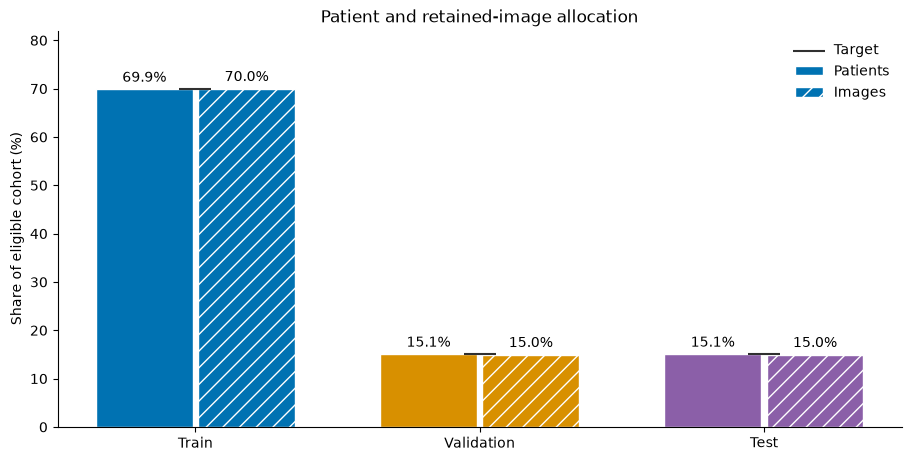

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
x = np.arange(len(SPLIT_ORDER))
for offset, metric, label, hatch in [(-0.18, 'patient_pct', 'Patients', ''), (0.18, 'image_pct', 'Images', '//')]:
    bars = ax.bar(x + offset, split_summary[metric], width=0.34, label=label,
                  color=[SPLIT_COLORS[s] for s in SPLIT_ORDER], hatch=hatch, edgecolor='white')
    ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.scatter(x, split_summary['target_pct'], color='#303030', marker='_', s=500, label='Target', zorder=5)
ax.set(xticks=x, xticklabels=[s.title() for s in SPLIT_ORDER], ylim=(0, 82),
       ylabel='Share of eligible cohort (%)', title='Patient and retained-image allocation')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()

### Balance within diagnosis / censoring strata

In [ ]:
stratum_summary = assigned_patients.group_by('baseline_diagnosis', 'is_censored', 'split').agg(
    pl.len().alias('patients'), pl.col('n_images').sum().alias('images')
).sort('baseline_diagnosis', 'is_censored', 'split')
display(stratum_summary.to_pandas())
bin_balance = images.join(assignments, on='ptid', validate='m:1').group_by('visit_num', 'split').len()
bin_balance = (bin_balance.to_pandas().pivot(index='visit_num', columns='split', values='len')
               .reindex(index=buckets['visit_num'].to_list(), columns=SPLIT_ORDER).fillna(0).astype(int))
bin_balance.index = buckets['visit_code'].to_list()
display(bin_balance.rename_axis('Scheduled bin'))

,baseline_diagnosis,is_censored,split,patients,images
0,CN,False,test,3,15
1,CN,False,train,12,74
2,CN,False,validation,3,15
3,CN,True,test,190,528
4,CN,True,train,884,2464
5,CN,True,validation,190,528
6,MCI,False,test,38,142
7,MCI,False,train,174,664
8,MCI,False,validation,38,142
9,MCI,True,test,166,518


split,train,validation,test
Scheduled bin,,,
BL,1842,397,397
v1,760,156,167
v2,789,165,164
v3,775,165,159
v4,299,73,78
v5,352,74,77
v6,110,27,25
v7,190,33,41
v8,135,34,27


### Compare with the previous split
Changing image counts can change patient assignments even when the seed and target ratios
stay fixed. Historical experiment cohorts remain historical; their scores should not be
presented as evaluations of this refreshed split.

In [ ]:
with engine.connect() as conn:
    if sqlalchemy.inspect(conn).has_table('train_test_split', schema='_raw'):
        previous = pl.read_database('SELECT ptid, split FROM _raw.train_test_split', conn)
    else:
        previous = pl.DataFrame(schema={'ptid': pl.String, 'split': pl.String})
comparison = assignments.join(previous.rename({'split': 'previous_split'}), on='ptid', how='left', validate='1:1')
display(pd.DataFrame({
    'Change': ['New patients', 'Existing patients changing split', 'Previous patients removed'],
    'Patients': [comparison['previous_split'].null_count(),
                 comparison.filter(pl.col('split') != pl.col('previous_split')).height,
                 previous.join(assignments, on='ptid', how='anti').height],
}))

,Change,Patients
0,New patients,0
1,Existing patients changing split,1182
2,Previous patients removed,0


### Persist and verify
Snapshot files contain the retained cohort, bucket schedule, assignments, prior assignments,
and content hashes under `data/artifacts/data_splits/<UTC timestamp>/` (git-ignored).
`latest.json` points to the most recent successful update. Database readback is verified
inside the transaction before commit.

In [ ]:
if WRITE_SPLITS:
    manifest = persist_splits(engine, images, buckets, assignments, ARTIFACT_DIR,
                              seed=SEED, proportions=SPLIT_PROPORTIONS)
    display(Markdown(f"**Saved and verified** `{manifest['destination']}`. "
                     f"Snapshot: `{manifest['snapshot_directory']}`."))
else:
    display(Markdown('**Preview only:** no assignments were written. Set WRITE_SPLITS=True to persist.'))

**Saved and verified** `_raw.train_test_split`. Snapshot: `C:\Users\Travis\Documents\Projects\alzheimers-diagnoses\data\artifacts\data_splits\20260926T202443358731Z`.

## Takeaways
The balance tables distinguish patient counts, image weights, and event rates; bin counts
are diagnostics, not an additional balancing objective. Run `data_viz.ipynb` to inspect
the saved cohort. Rebuild or verify tensor contents against the selected image IDs before
training; the existence check here cannot establish that tensor sequences are current.
The dbt nearest-image ranking currently has no explicit tie-breaker for equal distances,
so a dbt rebuild can change selected IDs; the visualization source-hash check detects that drift.